In [2]:

import json
import time
import requests

URL = "http://127.0.0.1:8000/v1/chat/completions"


def benchmark(prompt, name):
    payload = {
        "model": "smollm2",
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "max_tokens": 100,
        "temperature": 0,
        "stream": True,
        "stream_options": {"include_usage": True}
    }

    start = time.perf_counter()
    first_token_time = None
    content_events = 0
    usage = {}

    with requests.post(
        URL,
        
        json=payload,
        stream=True,
        timeout=180
    ) as response:

        response.raise_for_status()

        for line in response.iter_lines():
            if not line.startswith(b"data: "):
                continue

            data = line[6:]

            if data == b"[DONE]":
                break

            chunk = json.loads(data)

            if chunk.get("usage"):
                usage = chunk["usage"]

            for choice in chunk.get("choices", []):
                content = choice.get("delta", {}).get("content")

                if content:
                    if first_token_time is None:
                        first_token_time = time.perf_counter()

                    content_events += 1

    end = time.perf_counter()

    total = end - start
    ttft = first_token_time - start if first_token_time else 0

    output_tokens = usage.get("completion_tokens", 0)
    input_tokens = usage.get("prompt_tokens", 0)

    # Approximate average TPOT after first token
    tpot = (
        (end - first_token_time) / (output_tokens - 1)
        if first_token_time and output_tokens > 1
        else 0
    )

    print(f"\n=== {name} ===")
    print("Input tokens:", input_tokens)
    print("Output tokens:", output_tokens)
    print("TTFT:", round(ttft, 3), "s")
    print("Approx TPOT:", round(tpot * 1000, 2), "ms")
    print("Total latency:", round(total, 3), "s")
    print("Throughput:", round(output_tokens / total, 2), "tok/s")
    print("Streaming content events:", content_events)


short_prompt = "Explain transformers."

long_prompt = (
    "Explain how attention works in a transformer. "
    * 100
)

# Warm up inference
benchmark("Say hello.", "Warmup")

benchmark(short_prompt, "SHORT PROMPT")
benchmark(long_prompt, "LONG PROMPT")



=== Warmup ===
Input tokens: 33
Output tokens: 58
TTFT: 0.088 s
Approx TPOT: 24.57 ms
Total latency: 1.489 s
Throughput: 38.96 tok/s
Streaming content events: 57

=== SHORT PROMPT ===
Input tokens: 33
Output tokens: 100
TTFT: 0.125 s
Approx TPOT: 25.78 ms
Total latency: 2.678 s
Throughput: 37.34 tok/s
Streaming content events: 100

=== LONG PROMPT ===
Input tokens: 831
Output tokens: 100
TTFT: 0.063 s
Approx TPOT: 25.96 ms
Total latency: 2.633 s
Throughput: 37.99 tok/s
Streaming content events: 100


# Continous Batching 

In [7]:

import asyncio
import time
import statistics

import httpx

URL = "http://127.0.0.1:8000/v1/chat/completions"
CONCURRENCY_LEVELS = [1, 5, 10, 20]


async def generate(client, request_id):
    payload = {
        "model": "smollm2",
        "messages": [
            {
                "role": "user",
                "content": f"Request {request_id}: Explain how transformers work."
            }
        ],
        "max_tokens": 100,
        "min_tokens": 100,
        "temperature": 0,
    }

    start = time.perf_counter()

    response = await client.post(URL, json=payload)
    response.raise_for_status()

    latency = time.perf_counter() - start
    data = response.json()

    tokens = data["usage"]["completion_tokens"]

    return {
        "latency": latency,
        "tokens": tokens,
    }


async def benchmark(concurrency):
    async with httpx.AsyncClient(timeout=180) as client:
        start = time.perf_counter()

        results = await asyncio.gather(
            *[
                generate(client, i)
                for i in range(concurrency)
            ]
        )

        duration = time.perf_counter() - start

    total_tokens = sum(r["tokens"] for r in results)
    avg_latency = statistics.mean(r["latency"] for r in results)

    print(f"\n=== {concurrency} CONCURRENT REQUESTS ===")
    print(f"Total time: {duration:.2f} s")
    print(f"Average latency: {avg_latency:.2f} s")
    print(f"Throughput: {total_tokens / duration:.2f} tokens/s")
    print(f"Completed requests: {len(results)}")


async def main():
    # Warm up the engine
    async with httpx.AsyncClient(timeout=180) as client:
        await generate(client, "warmup")

    for concurrency in CONCURRENCY_LEVELS:
        await benchmark(concurrency)


await main()



=== 1 CONCURRENT REQUESTS ===
Total time: 2.87 s
Average latency: 2.87 s
Throughput: 34.87 tokens/s
Completed requests: 1

=== 5 CONCURRENT REQUESTS ===
Total time: 3.64 s
Average latency: 3.64 s
Throughput: 137.18 tokens/s
Completed requests: 5

=== 10 CONCURRENT REQUESTS ===
Total time: 6.31 s
Average latency: 4.38 s
Throughput: 158.37 tokens/s
Completed requests: 10

=== 20 CONCURRENT REQUESTS ===
Total time: 6.85 s
Average latency: 4.12 s
Throughput: 292.11 tokens/s
Completed requests: 20


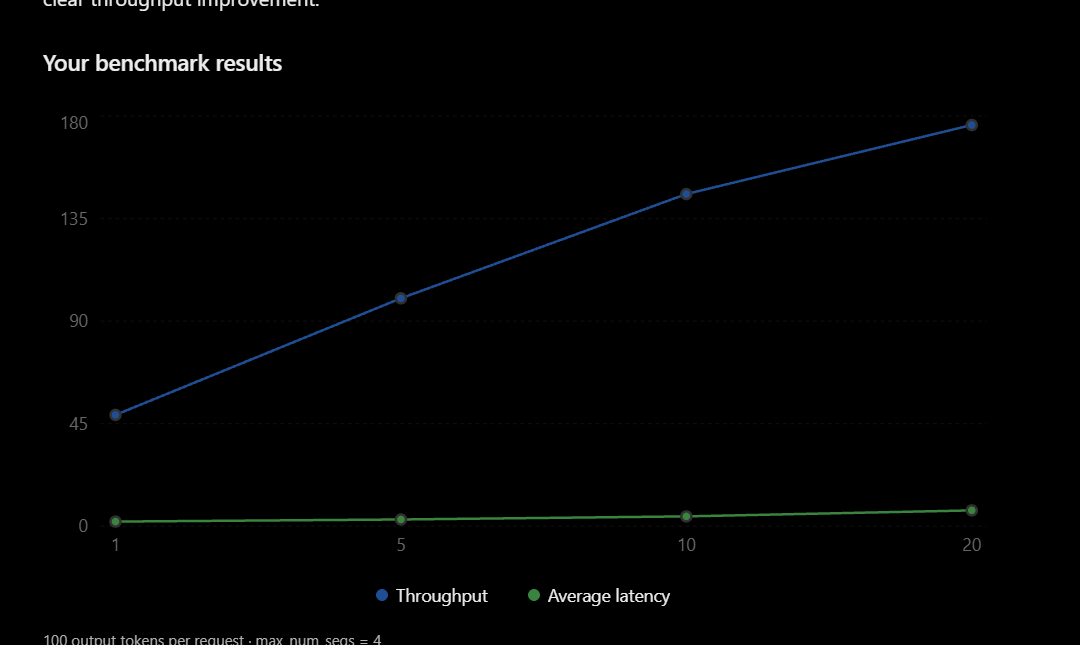

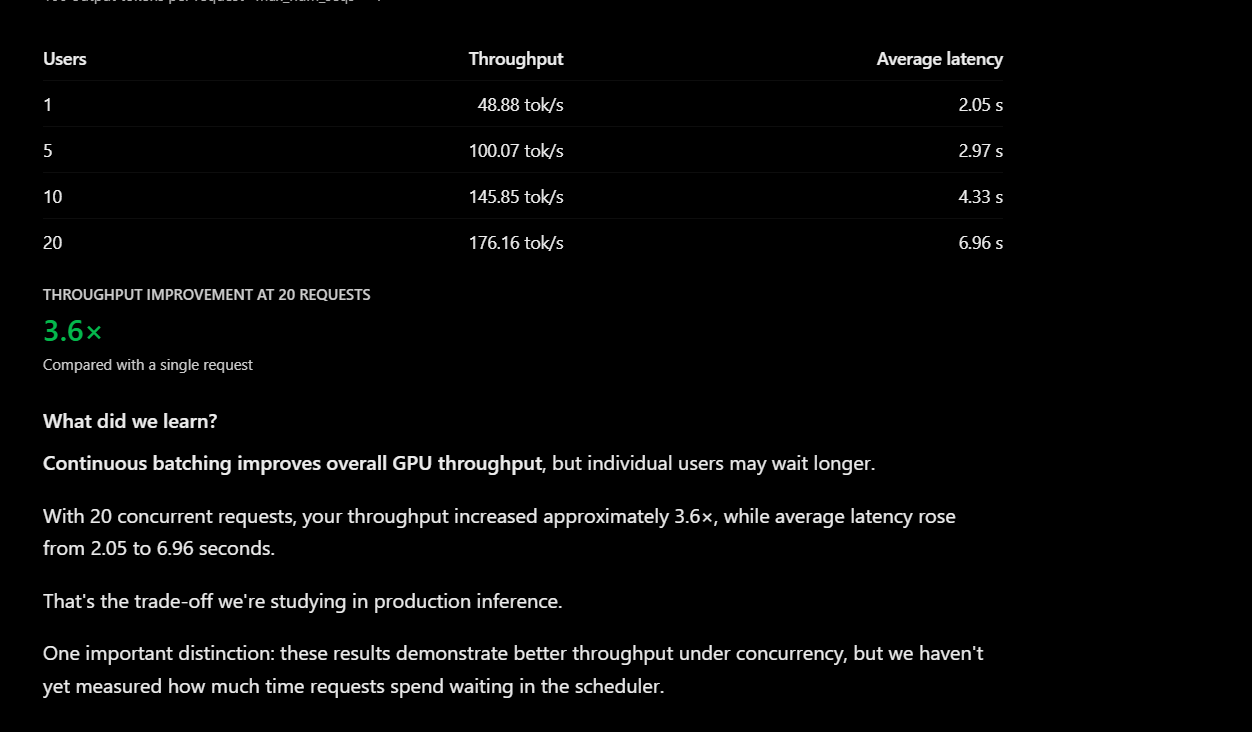